# Presynaptic 10 µm neighborhoods: five-fold morphology classification

All five folds completed **30 epochs**. Each input is seeded at an existing
**presynaptic site** and contains every available embedding within **10 µm
geodesic distance of its skeleton anchor**. The model shares a pointwise MLP
aggregation and ResNet trunk, appends the postsynaptic embedding, and trains
**five local heads across the full morphology hierarchy (13 leaf classes)**.

This notebook reads the completed reports, epoch curves, and saved all-head
predictions. It does not train models or change the database.

**Reading the results:** the held-out fold was also used to select the best
epoch, so it is not an untouched final test set. Fold means give each fold
equal weight; error bars show sample standard deviation across folds, not
confidence intervals for independent replicates. Local-head metrics are
conditioned on the **true parent**; end-to-end metrics include routing errors.
Windows use the training pipeline's per-cell membership-set deduplication.
A saved synapse ID identifies the representative of a unique window.

**Metric convention:** ordinary accuracy is omitted. Balanced accuracy
(mean recall over supported classes) is paired with **per-class precision**;
macro precision and macro F1 summarize comparisons. Precision is set to zero
when a class has no predictions, matching the trainer. Tables show predicted
counts and the number of folds with no predictions to make these cases visible.

In [1]:
%matplotlib inline
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'scripts/train_gnn.py').exists())
RUN = ROOT / 'analysis/presynaptic/latest100k_geodesic10um'
sys.path.insert(0, str(ROOT))
from data.dataset_lcpn import load_hierarchy
from gnn.metrics import balanced_accuracy, macro_precision, macro_f1, per_class_precision, per_class_recall
completion = json.loads((RUN / 'completion.json').read_text())
plan = json.loads((RUN / 'plan.json').read_text())
folds = sorted(completion['folds'], key=lambda r: r['fold'])
assert completion['complete'] and [r['fold'] for r in folds] == list(range(5))
assert all(r['completed_epochs'] == 30 for r in folds)
manifests = {i: json.loads((RUN / 'manifests' / f'fold{i}.json').read_text()) for i in range(5)}
hierarchy = load_hierarchy(manifests[0])
levels = completion['hierarchy']['level_classes']
heads = completion['hierarchy']['local_heads']
assert hierarchy.level_classes == levels and len(heads) == 5
leaf_names = levels[-1]
COLORS = plt.get_cmap('tab10').colors
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titlesize': 12})
pd.set_option('display.max_colwidth', 80)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 20)
def class_precision_table(matrices, names):
    rows = []
    for fold, matrix in enumerate(matrices):
        matrix = np.asarray(matrix)
        precision = per_class_precision(matrix)
        recall = per_class_recall(matrix)
        for i, name in enumerate(names):
            rows.append({'Fold': fold, 'Class': name, 'Precision': precision[i],
                         'Recall': recall[i], 'True count': int(matrix[i].sum()),
                         'Predicted count': int(matrix[:, i].sum()),
                         'No predictions': int(matrix[:, i].sum() == 0)})
    return pd.DataFrame(rows).groupby('Class', sort=False).agg(
        precision_mean=('Precision', 'mean'), precision_fold_SD=('Precision', 'std'),
        recall_mean=('Recall', 'mean'), recall_fold_SD=('Recall', 'std'),
        true_count=('True count', 'sum'), predicted_count=('Predicted count', 'sum'),
        folds_without_predictions=('No predictions', 'sum'))
def predictions_path(fold):
    return RUN / 'all_lcpn_predictions' / f'fold{fold}.parquet'
def checkpoint_path(record):
    # Prefer the current checkout when moved between lab mount aliases.
    suffix = str(record['checkpoint']).split('/results/', 1)[1]
    return ROOT / 'results' / suffix
for record in folds:
    assert pq.ParquetFile(predictions_path(record['fold'])).metadata.num_rows == record['classified_windows']
display(pd.Series({'Radius (µm)': completion['window_nm'] / 1000,
                   'Cells': plan['cells'], 'Folds': len(folds),
                   'Epochs per fold': 30, 'Learned local heads': len(heads),
                   'Leaf classes': len(leaf_names),
                   'Classified unique windows': completion['classified_windows']}).to_frame('Value'))

,Value
Radius (µm),10.0
Cells,2029.0
Folds,5.0
Epochs per fold,30.0
Learned local heads,5.0
Leaf classes,13.0
Classified unique windows,1746215.0


## Hierarchy and local classifiers

Each branching parent has a separate learned output head. Unary branches
(including the neuron-only root) pass through deterministically. Every head's
logits are saved for every window, including heads outside its predicted path.

In [2]:
head_table = pd.DataFrame([{'Head': i, 'Parent': h['parent_name'],
                            'Decision level': h['child_level'],
                            'Children': ', '.join(h['children'])} for i, h in enumerate(heads)])
display(head_table.set_index('Head'))
display(pd.DataFrame({'Level': range(len(levels)), 'Classes': [', '.join(x) for x in levels]}).set_index('Level'))

,Parent,Decision level,Children
Head,,,
0,neuron,1,"excitatory, inhibitory"
1,excitatory,2,"pyramidal, thalamocortical"
2,inhibitory,2,"BasketFam, BipFam, MartFam, NglFam"
3,pyramidal,3,"ET, IT, NP, corticothalamic"
4,IT,4,"L2IT, L3IT, L4IT, L5IT, L6IT"


,Classes
Level,
0,neuron
1,"excitatory, inhibitory"
2,"BasketFam, BipFam, MartFam, NglFam, pyramidal, thalamocortical"
3,"BasketFam, BipFam, ET, IT, MartFam, NP, NglFam, corticothalamic, thalamocort..."
4,"BasketFam, BipFam, L2IT, L3IT, L4IT, L5ET, L5IT, L5NP, L6CT, L6IT, MartFam, ..."


## Best-checkpoint performance by fold

Window metrics evaluate individual unique neighborhoods. Cell metrics are
the trainer's aggregation of predictions per cell. These tables use the
**13 leaf classes**. Best-epoch indices are zero-based.
Per-class precision for both evaluation units accompanies the aggregate scores.

,Best epoch (0-based),Held-out windows,Window balanced_accuracy,Window macro_precision,Window macro_f1,Cell balanced_accuracy,Cell macro_precision,Cell macro_f1
Fold,,,,,,,,
0,29,344572,0.5963,0.6359,0.6000,0.7999,0.8186,0.7926
1,28,356278,0.5861,0.6594,0.5997,0.7605,0.8380,0.7661
2,24,342378,0.5727,0.6503,0.5981,0.6869,0.8295,0.7187
3,20,349785,0.6077,0.6396,0.6159,0.7336,0.8414,0.7574
4,27,353202,0.5953,0.6409,0.6034,0.7785,0.8110,0.7814


,mean,fold SD
Window balanced_accuracy,0.5916,0.0131
Window macro_precision,0.6452,0.0095
Window macro_f1,0.6034,0.0072
Cell balanced_accuracy,0.7519,0.0437
Cell macro_precision,0.8277,0.0128
Cell macro_f1,0.7633,0.0284


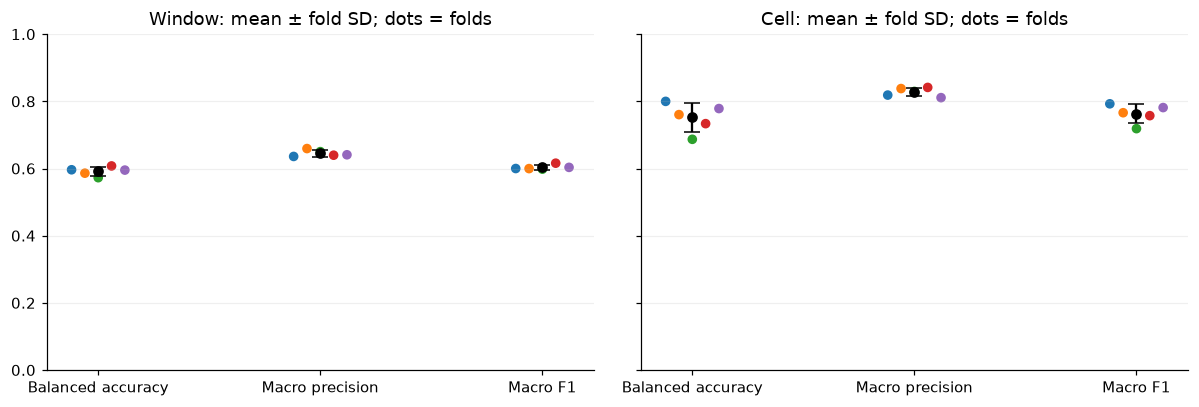

precision_mean  precision_fold_SD  recall_mean  \
Evaluation Class                                                             
Window     BasketFam                0.9454             0.0170       0.9690   
           BipFam                   0.7333             0.1367       0.7123   
           L2IT                     0.4739             0.0728       0.5015   
           L3IT                     0.4673             0.0674       0.3742   
           L4IT                     0.6594             0.0549       0.7318   
           L5ET                     0.7694             0.1008       0.5825   
           L5IT                     0.3877             0.0810       0.2639   
           L5NP                     0.2380             0.1455       0.0919   
           L6CT                     0.6777             0.0991       0.4399   
           L6IT                     0.4559             0.0769       0.5639   
           MartFam                  0.9171             0.0165       0.8647   
           NglFam                   0.7392             0.1009       0.6707   
           thalamocortical          0.9236             0.0128       0.9243   
Cell       BasketFam                0.9605             0.0154       0.9941   
           BipFam                   0.9489             0.0548       0.9300   
           L2IT                     0.8367             0.1267       0.7930   
           L3IT                     0.7915             0.1388       0.4829   
           L4IT                     0.7507             0.1294       0.9692   
           L5ET                     1.0000             0.0000       0.8836   
           L5IT                     0.9684             0.0706       0.3670   
           L5NP                     0.0000             0.0000       0.0000   
           L6CT                     0.9814             0.0297       0.7571   
           L6IT                     0.6534             0.1162       0.8864   
           MartFam                  0.9089             0.0660       0.8710   
           NglFam                   0.9600             0.0894       0.8400   
           thalamocortical          1.0000             0.0000       1.0000   

                            recall_fold_SD  true_count  predicted_count  \
Evaluation Class                                                          
Window     BasketFam                0.0047      528836           542339   
           BipFam                   0.0931       75629            74047   
           L2IT                     0.0746      108481           118691   
           L3IT                     0.0922      107396            89040   
           L4IT                     0.0880      290573           325486   
           L5ET                     0.1120       14007            10917   
           L5IT                     0.0732       72221            53035   
           L5NP                     0.0836        3815             1679   
           L6CT                     0.0676       33368            22512   
           L6IT                     0.0622       61339            78709   
           MartFam                  0.0243      357799           337297   
           NglFam                   0.1050       10698             9596   
           thalamocortical          0.0572       82053            82867   
Cell       BasketFam                0.0132         171              177   
           BipFam                   0.0900         113              111   
           L2IT                     0.1539         268              264   
           L3IT                     0.1665         219              141   
           L4IT                     0.0393         522              693   
           L5ET                     0.1278          51               45   
           L5IT                     0.1904         116               46   
           L5NP                     0.0000          10                0   
           L6CT                     0.1145         244              189   
           L6IT                     0.1008 

In [3]:
rows = []
for record in folds:
    rows.append({'Fold': record['fold'], 'Best epoch (0-based)': record['best_epoch'],
                 'Held-out windows': record['classified_windows'],
                 **{f'{unit} {metric}': record[key][metric]
                    for unit, key in [('Window', 'window_metrics'), ('Cell', 'cell_metrics')]
                    for metric in ['balanced_accuracy', 'macro_precision', 'macro_f1']}})
scores = pd.DataFrame(rows).set_index('Fold')
display(scores.round(4))
metric_columns = [c for c in scores if c.startswith(('Window ', 'Cell '))]
display(scores[metric_columns].agg(['mean', 'std']).T.rename(columns={'std': 'fold SD'}).round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, unit in zip(axes, ['Window', 'Cell']):
    for i, metric in enumerate(['balanced_accuracy', 'macro_precision', 'macro_f1']):
        values = scores[f'{unit} {metric}'].to_numpy()
        ax.errorbar(i, values.mean(), yerr=values.std(ddof=1), fmt='o', color='black', capsize=5)
        ax.scatter(i + np.linspace(-.12, .12, 5), values, c=COLORS[:5], s=28)
    ax.set_xticks(range(3), ['Balanced accuracy', 'Macro precision', 'Macro F1'])
    ax.set_title(f'{unit}: mean ± fold SD; dots = folds')
    ax.set_ylim(0, 1)
    ax.grid(axis='y', alpha=.2)
fig.tight_layout()
plt.show()
leaf_precision = pd.concat({unit: class_precision_table(
    [record[key]['confusion_matrix'] for record in folds], leaf_names)
    for unit, key in [('Window', 'window_metrics'), ('Cell', 'cell_metrics')]},
    names=['Evaluation', 'Class'])
display(leaf_precision.round(4))
for record in folds:
    for key in ['window_metrics', 'cell_metrics']:
        actual = per_class_precision(np.asarray(record[key]['confusion_matrix']))
        np.testing.assert_allclose(actual, [record[key]['per_class_precision'][name] for name in leaf_names])

## Training curves

Curves include all 30 epochs; markers locate the selected checkpoint in
each fold. Validation here is the same cell-held-out fold reported above.

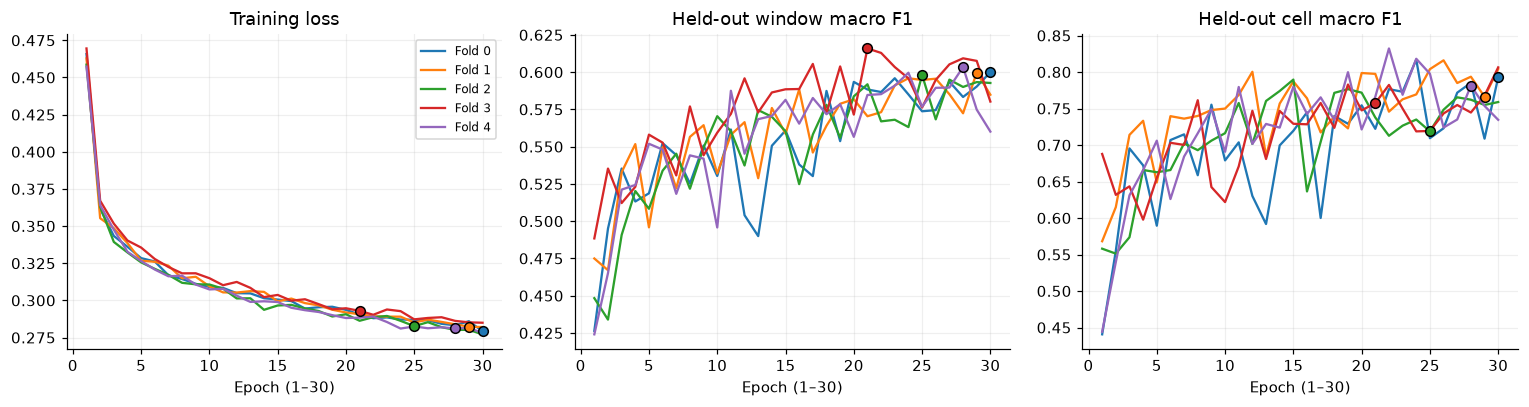

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for record in folds:
    frame = pd.read_csv(checkpoint_path(record).parent / 'epoch_metrics.csv')
    assert set(frame.epoch) == set(range(30))
    for ax, metric, title in zip(axes, ['train_loss', 'window_macro_f1', 'cell_macro_f1'],
                                 ['Training loss', 'Held-out window macro F1', 'Held-out cell macro F1']):
        ax.plot(frame.epoch + 1, frame[metric], color=COLORS[record['fold']], label=f"Fold {record['fold']}")
        best = frame.loc[frame.epoch == record['best_epoch']].iloc[-1]
        ax.scatter(best.epoch + 1, best[metric], color=COLORS[record['fold']], edgecolor='black', s=40, zorder=3)
        ax.set(title=title, xlabel='Epoch (1–30)')
        ax.grid(alpha=.2)
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

## End-to-end predictions at each hierarchy level

We collapse the saved **window-level leaf confusion matrices** to each
ancestor level. This measures the full predicted route, including upstream
errors. It is not conditional local-head performance. The constant neuron-only
root is omitted from the plot.
Per-class precision is reported separately for each level's class vocabulary.

balanced_accuracy         macro_precision         macro_f1  \
                           mean     std            mean     std     mean   
Level Classes                                                              
0     1                  1.0000  0.0000          1.0000  0.0000   1.0000   
1     2                  0.9705  0.0026          0.9693  0.0017   0.9698   
2     6                  0.8507  0.0153          0.8683  0.0194   0.8550   
3     9                  0.6900  0.0096          0.7625  0.0151   0.7124   
4     13                 0.5916  0.0131          0.6452  0.0095   0.6034   

                       
                  std  
Level Classes          
0     1        0.0000  
1     2        0.0020  
2     6        0.0158  
3     9        0.0090  
4     13       0.0072

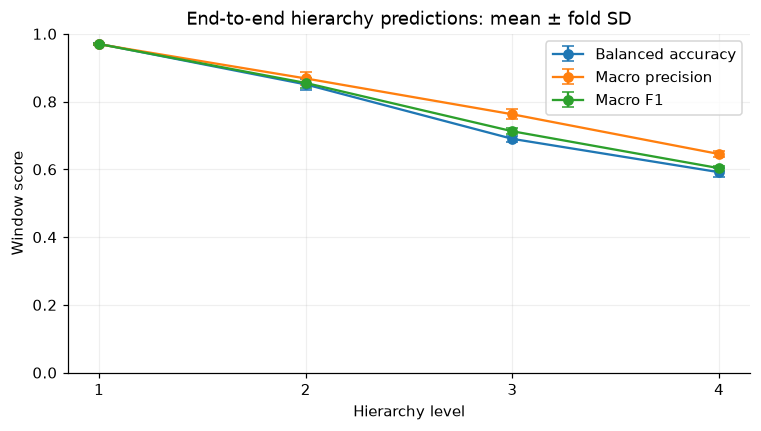

precision_mean  precision_fold_SD  recall_mean  \
Level Class                                                             
1     excitatory               0.9606             0.0072       0.9727   
      inhibitory               0.9781             0.0078       0.9683   
2     BasketFam                0.9454             0.0170       0.9690   
      BipFam                   0.7333             0.1367       0.7123   
      MartFam                  0.9171             0.0165       0.8647   
      NglFam                   0.7392             0.1009       0.6707   
      pyramidal                0.9510             0.0089       0.9634   
      thalamocortical          0.9236             0.0128       0.9243   
3     BasketFam                0.9454             0.0170       0.9690   
      BipFam                   0.7333             0.1367       0.7123   
      ET                       0.7694             0.1008       0.5825   
      IT                       0.9189             0.0062       0.9549   
      MartFam                  0.9171             0.0165       0.8647   
      NP                       0.2380             0.1455       0.0919   
      NglFam                   0.7392             0.1009       0.6707   
      corticothalamic          0.6777             0.0991       0.4399   
      thalamocortical          0.9236             0.0128       0.9243   
4     BasketFam                0.9454             0.0170       0.9690   
      BipFam                   0.7333             0.1367       0.7123   
      L2IT                     0.4739             0.0728       0.5015   
      L3IT                     0.4673             0.0674       0.3742   
      L4IT                     0.6594             0.0549       0.7318   
      L5ET                     0.7694             0.1008       0.5825   
      L5IT                     0.3877             0.0810       0.2639   
      L5NP                     0.2380             0.1455       0.0919   
      L6CT                     0.6777             0.0991       0.4399   
      L6IT                     0.4559             0.0769       0.5639   
      MartFam                  0.9171             0.0165       0.8647   
      NglFam                   0.7392             0.1009       0.6707   
      thalamocortical          0.9236             0.0128       0.9243   

                       recall_fold_SD  true_count  predicted_count  \
Level Class                                                          
1     excitatory               0.0095      773253           782936   
      inhibitory               0.0062      972962           963279   
2     BasketFam                0.0047      528836           542339   
      BipFam                   0.0931       75629            74047   
      MartFam                  0.0243      357799           337297   
      NglFam                   0.1050       10698             9596   
      pyramidal                0.0111      691200           700069   
      thalamocortical          0.0572       82053            82867   
3     BasketFam                0.0047      528836           542339   
      BipFam                   0.0931       75629            74047   
      ET                       0.1120       14007            10917   
      IT                       0.0093      640010           664961   
      MartFam                  0.0243      357799           337297   
      NP                       0.0836        3815             1679   
      NglFam                   0.1050       10698             9596   
      corticothalamic          0.0676       33368            22512   
      thalamocortical          0.0572       82053            82867   
4     BasketFam                0.0047      528836           542339   
      BipFam                   0.0931       75629            74047   
      L2IT                     0.0746      108481           118691   
      L3IT                     0.0922      107396            89040   
      L4IT                     0.0880      290573           325486   
      

In [5]:
def matrix_metrics(matrix):
    matrix = np.asarray(matrix)
    return {'balanced_accuracy': balanced_accuracy(matrix),
            'macro_precision': macro_precision(matrix), 'macro_f1': macro_f1(matrix)}
level_matrices = {}
level_rows = []
for record in folds:
    leaf = np.asarray(record['window_metrics']['confusion_matrix'])
    assert leaf.shape == (len(leaf_names), len(leaf_names))
    for level, names in enumerate(levels):
        ancestors = np.array([hierarchy.level_maps[level][hierarchy.label_paths[name][level]] for name in leaf_names])
        collapsed = np.zeros((len(names), len(names)), dtype=np.int64)
        np.add.at(collapsed, (ancestors[:, None], ancestors[None, :]), leaf)
        assert collapsed.sum() == record['classified_windows']
        level_matrices[(record['fold'], level)] = collapsed
        level_rows.append({'Fold': record['fold'], 'Level': level, 'Classes': len(names), **matrix_metrics(collapsed)})
    assert np.isclose(matrix_metrics(leaf)['macro_f1'], record['window_metrics']['macro_f1'])
level_scores = pd.DataFrame(level_rows)
display(level_scores.groupby(['Level', 'Classes'])[['balanced_accuracy', 'macro_precision', 'macro_f1']].agg(['mean', 'std']).round(4))
fig, ax = plt.subplots(figsize=(8, 4))
for metric, label in [('balanced_accuracy', 'Balanced accuracy'), ('macro_precision', 'Macro precision'), ('macro_f1', 'Macro F1')]:
    grouped = level_scores.query('Level > 0').groupby('Level')[metric].agg(['mean', 'std'])
    ax.errorbar(grouped.index, grouped['mean'], yerr=grouped['std'], marker='o', capsize=4, label=label)
ax.set(xticks=range(1, len(levels)), xlabel='Hierarchy level', ylabel='Window score', ylim=(0, 1),
       title='End-to-end hierarchy predictions: mean ± fold SD')
ax.legend()
ax.grid(alpha=.2)
plt.show()
level_precision = pd.concat({level: class_precision_table(
    [level_matrices[(fold, level)] for fold in range(5)], names)
    for level, names in enumerate(levels) if level > 0}, names=['Level', 'Class'])
display(level_precision.round(4))

## Every local head, conditioned on its true parent

A head is evaluated on windows whose true label lies under that parent,
regardless of upstream predictions. This separates local discrimination
from routing errors. Support counts sum across the disjoint held-out folds.
Precision here is conditional on the true parent, just like the head's
balanced accuracy; it is not end-to-end precision for that class.

,held_out_support,balanced_accuracy,balanced_accuracy_fold_SD,macro_precision,macro_precision_fold_SD,macro_F1,macro_F1_fold_SD
Parent,,,,,,,
neuron,1746215,0.9705,0.0026,0.9693,0.0017,0.9698,0.0020
excitatory,773253,0.9606,0.0272,0.9637,0.0037,0.9617,0.0139
inhibitory,972962,0.8350,0.0112,0.8404,0.0228,0.8321,0.0194
pyramidal,691200,0.5499,0.0177,0.6945,0.0365,0.5982,0.0237
IT,640010,0.5168,0.0175,0.5395,0.0156,0.5138,0.0183


precision_mean  precision_fold_SD  recall_mean  \
True parent Child class                                                       
neuron      excitatory               0.9606             0.0072       0.9727   
            inhibitory               0.9781             0.0078       0.9683   
excitatory  pyramidal                0.9925             0.0043       0.9922   
            thalamocortical          0.9350             0.0092       0.9290   
inhibitory  BasketFam                0.9486             0.0167       0.9723   
            BipFam                   0.7505             0.1027       0.8088   
            MartFam                  0.9309             0.0224       0.8839   
            NglFam                   0.7317             0.1039       0.6751   
pyramidal   ET                       0.8408             0.0823       0.6556   
            IT                       0.9621             0.0029       0.9869   
            NP                       0.2598             0.1443       0.1049   
            corticothalamic          0.7154             0.0969       0.4522   
IT          L2IT                     0.5115             0.0824       0.5204   
            L3IT                     0.4891             0.0691       0.3799   
            L4IT                     0.6929             0.0477       0.7494   
            L5IT                     0.4189             0.0778       0.2778   
            L6IT                     0.5849             0.0991       0.6564   

                             recall_fold_SD  true_count  predicted_count  \
True parent Child class                                                    
neuron      excitatory               0.0095      773253           782932   
            inhibitory               0.0062      972962           963283   
excitatory  pyramidal                0.0022      691200           691008   
            thalamocortical          0.0565       82053            82245   
inhibitory  BasketFam                0.0054      528836           542367   
            BipFam                   0.0972       75629            81237   
            MartFam                  0.0194      357799           339612   
            NglFam                   0.1059       10698             9746   
pyramidal   ET                       0.0848       14007            11061   
            IT                       0.0052      640010           656578   
            NP                       0.0953        3815             1695   
            corticothalamic          0.0678       33368            21866   
IT          L2IT                     0.0855      108481           114652   
            L3IT                     0.0919      107396            86141   
            L4IT                     0.0851      290573           316131   
            L5IT                     0.0787       72221            51400   
            L6IT                     0.0549       61339            71686   

                             folds_without_predictions  
True parent Child class                                 
neuron      excitatory                               0  
            inhibitory                               0  
excitatory  pyramidal                                0  
            thalamocortical                          0  
inhibitory  BasketFam                                0  
            BipFam                                   0  
            MartFam                                  0  
            NglFam                                   0  
pyramidal   ET                                       0  
            IT                                       0  
            NP                                       0  
            corticothalamic                          0  
IT          L2IT                                     0  
            L3IT                                     0  
            L4IT                                     0  
            L5IT                                     0  
            L6IT                                     0

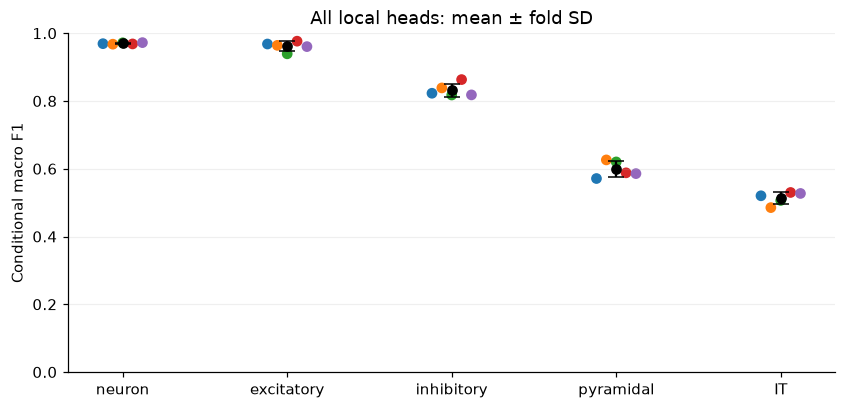

In [6]:
head_rows = []
head_matrices = {}
for record in folds:
    for i, metrics in enumerate(record['local_head_metrics']):
        assert metrics['parent'] == heads[i]['parent_name'] and metrics['children'] == heads[i]['children']
        matrix = np.asarray(metrics['confusion_matrix'])
        assert matrix.sum() == metrics['support']
        head_matrices[(record['fold'], i)] = matrix
        head_rows.append({'Fold': record['fold'], 'Head': i, 'Parent': metrics['parent'],
                          'Support': metrics['support'], **matrix_metrics(matrix)})
head_scores = pd.DataFrame(head_rows)
display(head_scores.groupby('Parent', sort=False).agg(
    held_out_support=('Support', 'sum'), balanced_accuracy=('balanced_accuracy', 'mean'),
    balanced_accuracy_fold_SD=('balanced_accuracy', 'std'),
    macro_precision=('macro_precision', 'mean'), macro_precision_fold_SD=('macro_precision', 'std'),
    macro_F1=('macro_f1', 'mean'), macro_F1_fold_SD=('macro_f1', 'std')).round(4))
head_precision = pd.concat({head['parent_name']: class_precision_table(
    [head_matrices[(fold, i)] for fold in range(5)], head['children'])
    for i, head in enumerate(heads)}, names=['True parent', 'Child class'])
display(head_precision.round(4))
fig, ax = plt.subplots(figsize=(9, 4))
for i, head in enumerate(heads):
    group = head_scores[head_scores.Head == i]
    values = group.macro_f1.to_numpy()
    ax.errorbar(i, values.mean(), yerr=values.std(ddof=1), fmt='o', color='black', capsize=5)
    ax.scatter(i + np.linspace(-.12, .12, 5), values, c=COLORS[:5])
ax.set(xticks=range(len(heads)), xticklabels=[h['parent_name'] for h in heads],
       ylabel='Conditional macro F1', ylim=(0, 1), title='All local heads: mean ± fold SD')
ax.grid(axis='y', alpha=.2)
plt.show()

## Confusion matrices and per-class precision

Rows are true classes and columns are predictions. Each fold is normalized
by its own row support **before** taking the equal-weight mean. Unsupported
rows are omitted from that row's mean rather than counted as zero recall.
These row-normalized matrices show recall; the precision panels below use
predicted-class counts as their denominator.

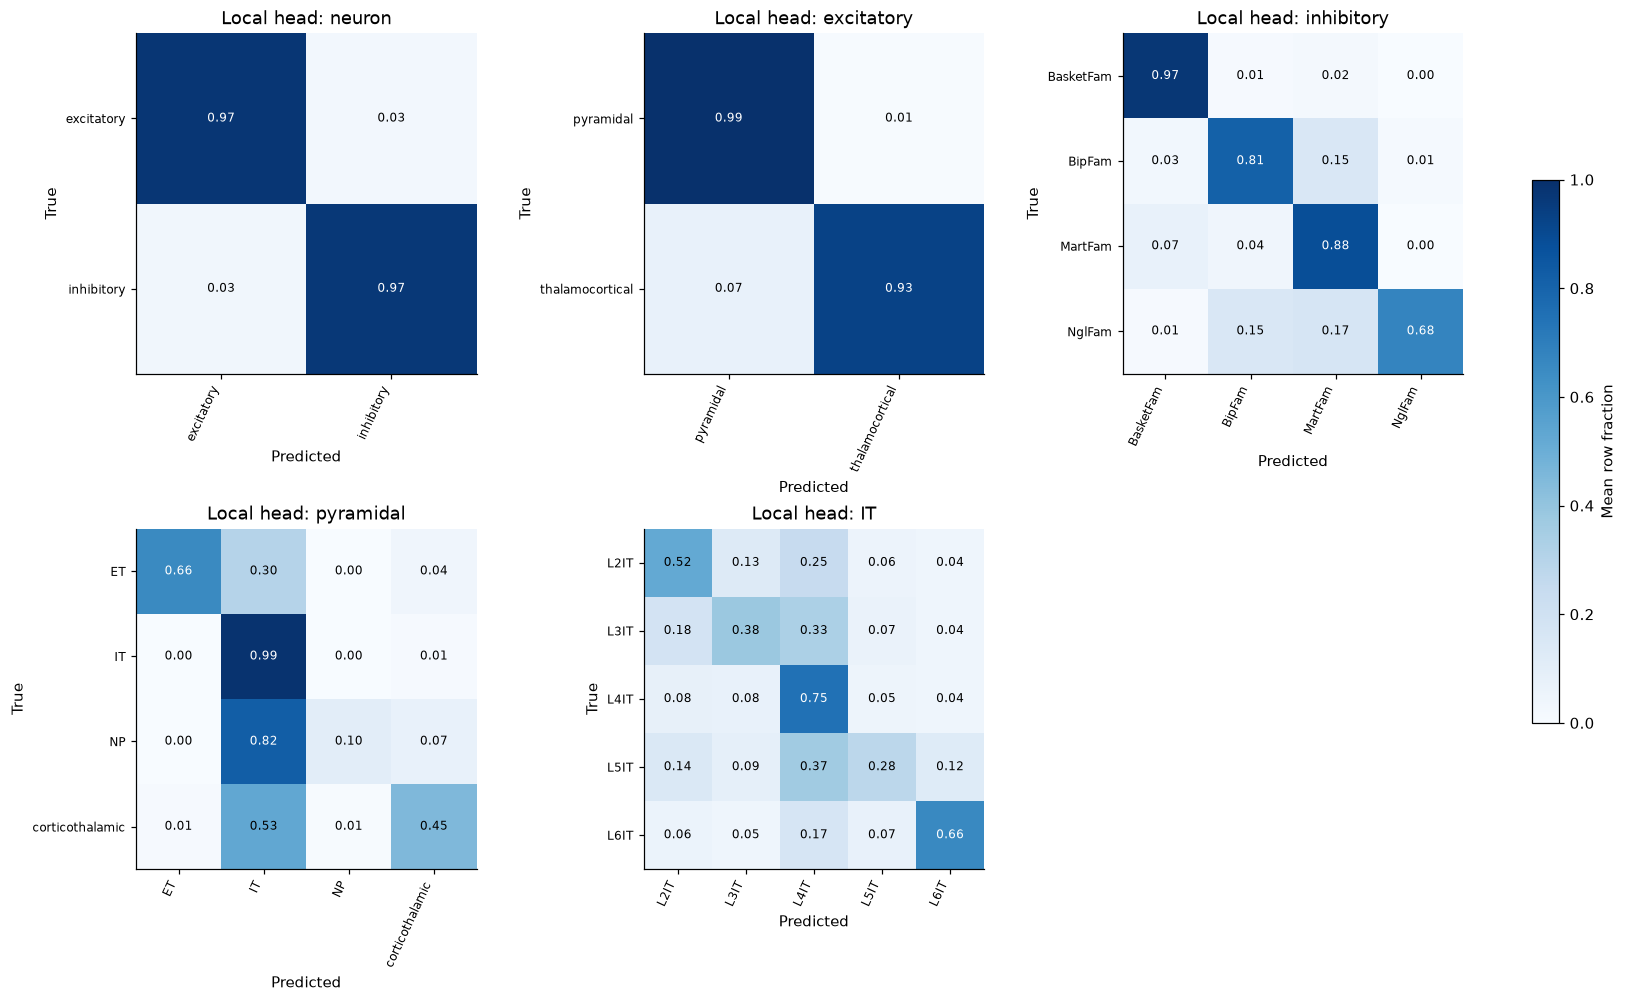

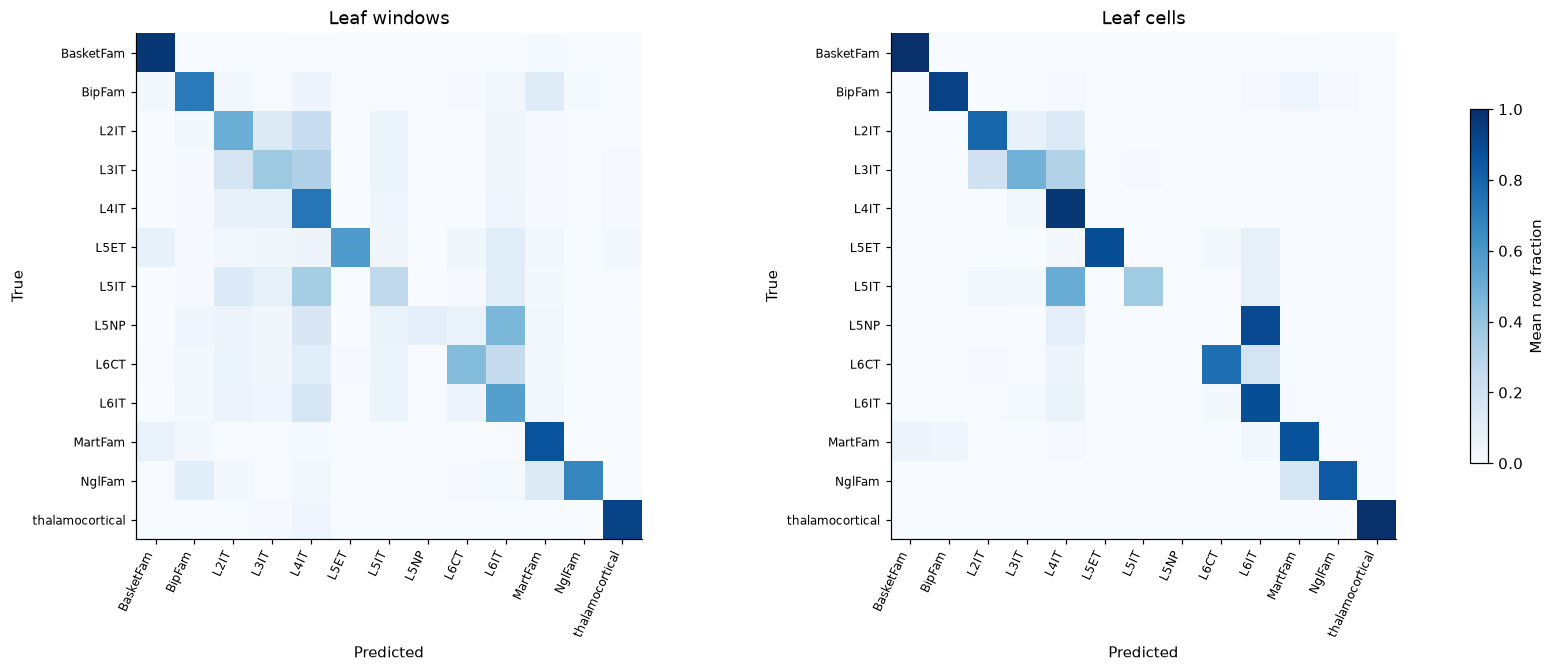

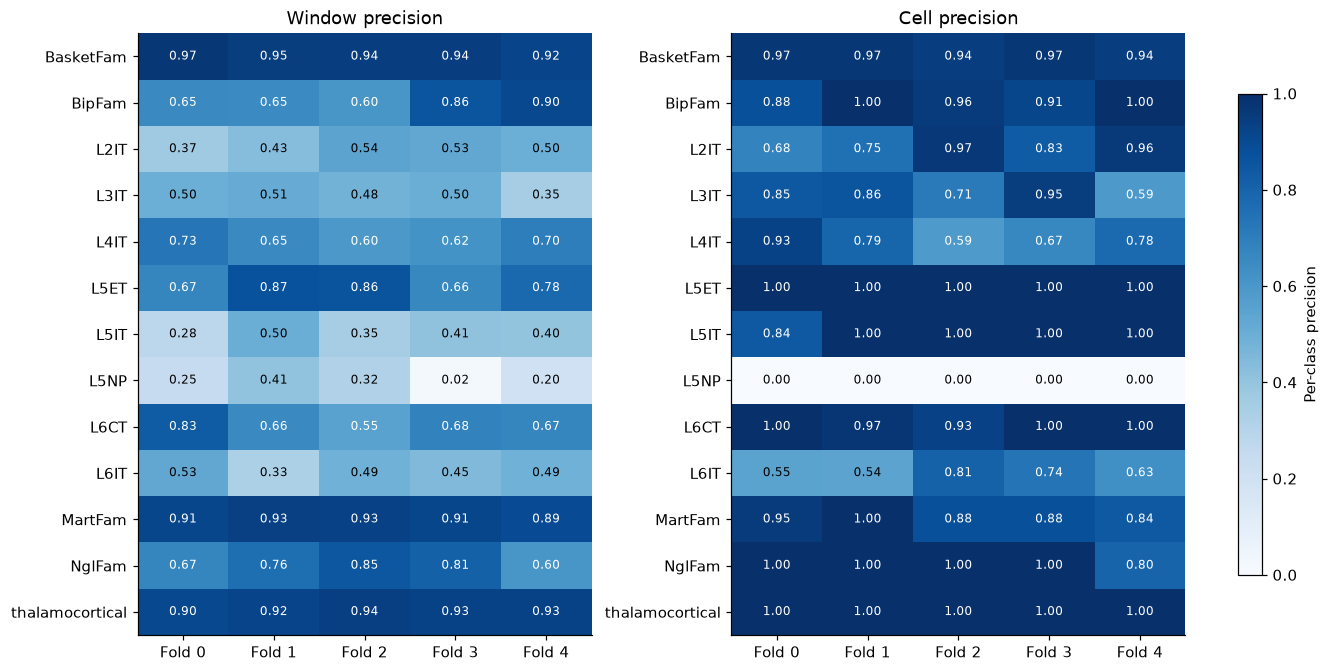

In [7]:
def mean_normalized(matrices):
    normalized = []
    for matrix in matrices:
        matrix = np.asarray(matrix, dtype=float)
        support = matrix.sum(1, keepdims=True)
        normalized.append(np.divide(matrix, support, out=np.full_like(matrix, np.nan), where=support > 0))
    return np.nanmean(normalized, axis=0)
def draw_matrix(ax, matrix, names, title, annotate=False):
    image = ax.imshow(matrix, vmin=0, vmax=1, cmap='Blues')
    ax.set(xticks=range(len(names)), yticks=range(len(names)), xticklabels=names, yticklabels=names,
           xlabel='Predicted', ylabel='True', title=title)
    plt.setp(ax.get_xticklabels(), rotation=65, ha='right', fontsize=8)
    plt.setp(ax.get_yticklabels(), fontsize=8)
    if annotate:
        for (i, j), value in np.ndenumerate(matrix):
            if np.isfinite(value):
                ax.text(j, i, f'{value:.2f}', ha='center', va='center', fontsize=8,
                        color='white' if value > .55 else 'black')
    return image
fig, axes = plt.subplots(2, 3, figsize=(15, 9), layout='constrained')
for i, head in enumerate(heads):
    matrix = mean_normalized([head_matrices[(f, i)] for f in range(5)])
    image = draw_matrix(axes.flat[i], matrix, head['children'], f"Local head: {head['parent_name']}", True)
axes.flat[-1].axis('off')
fig.colorbar(image, ax=list(axes.flat[:-1]), shrink=.65, label='Mean row fraction')
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout='constrained')
for ax, key, title in zip(axes, ['window_metrics', 'cell_metrics'], ['Leaf windows', 'Leaf cells']):
    matrix = mean_normalized([record[key]['confusion_matrix'] for record in folds])
    image = draw_matrix(ax, matrix, leaf_names, title)
fig.colorbar(image, ax=axes.tolist(), shrink=.7, label='Mean row fraction')
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 6), layout='constrained')
for ax, key, title in zip(axes, ['window_metrics', 'cell_metrics'], ['Window precision', 'Cell precision']):
    precision = pd.DataFrame({f"Fold {r['fold']}": r[key]['per_class_precision'] for r in folds}).reindex(leaf_names)
    image = ax.imshow(precision.to_numpy(), vmin=0, vmax=1, cmap='Blues', aspect='auto')
    ax.set(xticks=range(5), xticklabels=precision.columns, yticks=range(len(leaf_names)),
           yticklabels=leaf_names, title=title)
    for (i, j), value in np.ndenumerate(precision.to_numpy()):
        ax.text(j, i, f'{value:.2f}', ha='center', va='center', fontsize=8,
                color='white' if value > .55 else 'black')
fig.colorbar(image, ax=axes.tolist(), shrink=.8, label='Per-class precision')
plt.show()

## Number of embeddings per window

This reads only the `n_embeddings` column, in batches, from the saved
predictions. Counts describe eligible, deduplicated held-out windows rather
than every raw synapse. The ten-embedding line is a reference to the previous
selection rule, not a matched model-performance comparison.

,Value
Mean embeddings,10.443895
10th percentile,7.000000
Median,11.000000
90th percentile,13.000000
Maximum,39.000000
Fraction below 10,0.329011


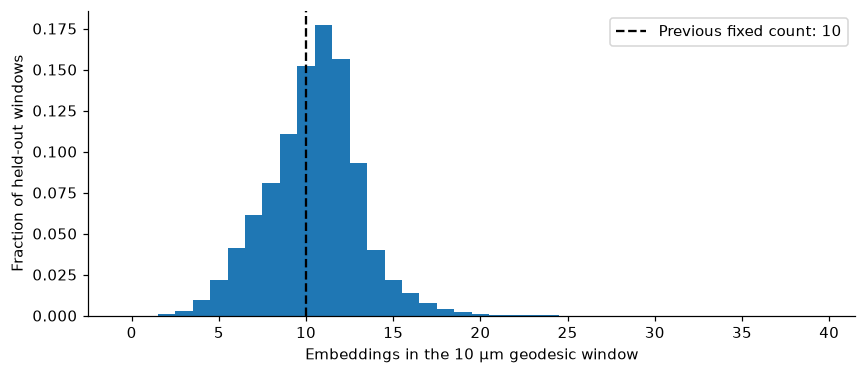

In [8]:
size_counts = {}
for record in folds:
    histogram = np.zeros(plan['maximum_embeddings'] + 1, np.int64)
    for batch in pq.ParquetFile(predictions_path(record['fold'])).iter_batches(columns=['n_embeddings'], batch_size=65536):
        sizes = batch.column(0).to_numpy()
        assert (sizes > 0).all() and sizes.max() <= plan['maximum_embeddings']
        histogram += np.bincount(sizes, minlength=len(histogram))
    assert histogram.sum() == record['classified_windows']
    size_counts[record['fold']] = histogram
counts = sum(size_counts.values())
x = np.arange(len(counts))
quantiles = x[np.searchsorted(np.cumsum(counts), np.array([.1, .5, .9]) * counts.sum())]
display(pd.Series({'Mean embeddings': np.dot(x, counts) / counts.sum(),
                   '10th percentile': quantiles[0], 'Median': quantiles[1],
                   '90th percentile': quantiles[2], 'Maximum': x[counts > 0].max(),
                   'Fraction below 10': counts[:10].sum() / counts.sum()}).to_frame('Value'))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(x, counts / counts.sum(), width=1, color=COLORS[0])
ax.axvline(10, color='black', linestyle='--', label='Previous fixed count: 10')
ax.set(xlabel='Embeddings in the 10 µm geodesic window', ylabel='Fraction of held-out windows')
ax.legend()
plt.show()

## Inspect saved logits from every head

Edit `FOLD`, `N_ROWS` and `ROW` below. The preview takes the first rows for
inspection, **not a representative random sample**. Logits are local raw
scores; the associated softmax probabilities are conditional on the head's
parent. Do not softmax logits from different heads together. Joint
probabilities multiply the relevant probabilities along the hierarchy.
An off-path head still has logits, but its conditional decision is not a
claim that the window belongs to that parent.

In [9]:
FOLD = 0
N_ROWS = 8
ROW = 0
assert 0 <= FOLD < 5 and 0 <= ROW < N_ROWS
sample = next(pq.ParquetFile(predictions_path(FOLD)).iter_batches(batch_size=N_ROWS)).to_pandas()
preview = sample[['root_id', 'synapse_id', 'window_row', 'n_embeddings']].copy()
preview['true_leaf'] = [manifests[FOLD]['cells'][str(int(rid))]['cell_type'] for rid in sample.root_id]
preview['predicted_leaf'] = [leaf_names[int(path[-1])] for path in sample.top_down_predictions]
display(preview)
row = sample.iloc[ROW]
truth = hierarchy.label_paths[preview.iloc[ROW].true_leaf]
local_rows = []
for i, head in enumerate(heads):
    logits = np.asarray(row[f'head_{i}_logits'])
    probabilities = np.asarray(row[f'head_{i}_probabilities'])
    assert len(logits) == head['n_children'] and np.isclose(probabilities.sum(), 1, atol=1e-6)
    on_path = head['parent_level'] < 0 or truth[head['parent_level']] == head['parent_name']
    for child, logit, probability in zip(head['children'], logits, probabilities):
        local_rows.append({'Head parent': head['parent_name'], 'On true parent path': on_path,
                           'Child': child, 'Logit': float(logit), 'Conditional probability': float(probability)})
display(pd.DataFrame(local_rows).set_index(['Head parent', 'Child']).round(5))
joint_rows = []
for level, names in enumerate(levels):
    probabilities = np.asarray(row[f'level_{level}_joint_probabilities'])
    assert np.isclose(probabilities.sum(), 1, atol=1e-5)
    selected = int(row.top_down_predictions[level])
    for i, (name, probability) in enumerate(zip(names, probabilities)):
        joint_rows.append({'Level': level, 'Class': name, 'Joint probability': float(probability),
                           'Top-down selection': i == selected})
display(pd.DataFrame(joint_rows).set_index(['Level', 'Class']).round(5))

,root_id,synapse_id,window_row,n_embeddings,true_leaf,predicted_leaf
0,864691134887444986,170338832,0,10,NglFam,BipFam
1,864691134887444986,185839131,1,14,NglFam,BipFam
2,864691134887444986,233361721,2,16,NglFam,NglFam
3,864691134887444986,171354532,3,14,NglFam,NglFam
4,864691134887444986,185511685,5,8,NglFam,NglFam
5,864691134887444986,202647217,6,8,NglFam,NglFam
6,864691134887444986,157533101,7,15,NglFam,NglFam
7,864691134887444986,160833627,8,14,NglFam,NglFam


On true parent path    Logit  \
Head parent Child                                           
neuron      excitatory                      True -1.66014   
            inhibitory                      True  2.89226   
excitatory  pyramidal                      False  2.24873   
            thalamocortical                False -1.26599   
inhibitory  BasketFam                       True -2.72212   
            BipFam                          True  2.31805   
            MartFam                         True -2.03231   
            NglFam                          True  1.06497   
pyramidal   ET                             False -3.25860   
            IT                             False  1.75389   
            NP                             False -3.47971   
            corticothalamic                False -1.32750   
IT          L2IT                           False  1.08241   
            L3IT                           False  0.76350   
            L4IT                           False  1.09327   
            L5IT                           False -0.12301   
            L6IT                           False -2.28911   

                             Conditional probability  
Head parent Child                                     
neuron      excitatory                       0.01043  
            inhibitory                       0.98957  
excitatory  pyramidal                        0.97110  
            thalamocortical                  0.02890  
inhibitory  BasketFam                        0.00496  
            BipFam                           0.76629  
            MartFam                          0.00989  
            NglFam                           0.21887  
pyramidal   ET                               0.00629  
            IT                               0.94528  
            NP                               0.00504  
            corticothalamic                  0.04338  
IT          L2IT                             0.32554  
            L3IT                             0.23665  
            L4IT                             0.32910  
            L5IT                             0.09752  
            L6IT                             0.01118

Joint probability  Top-down selection
Level Class                                                 
0     neuron                     1.00000                True
1     excitatory                 0.01043               False
      inhibitory                 0.98957                True
2     BasketFam                  0.00491               False
      BipFam                     0.75829                True
      MartFam                    0.00978               False
      NglFam                     0.21658               False
      pyramidal                  0.01013               False
      thalamocortical            0.00030               False
3     BasketFam                  0.00491               False
      BipFam                     0.75829                True
      ET                         0.00006               False
      IT                         0.00958               False
      MartFam                    0.00978               False
      NP                         0.00005               False
      NglFam                     0.21658               False
      corticothalamic            0.00044               False
      thalamocortical            0.00030               False
4     BasketFam                  0.00491               False
      BipFam                     0.75829                True
      L2IT                       0.00312               False
      L3IT                       0.00227               False
      L4IT                       0.00315               False
      L5ET                       0.00006               False
      L5IT                       0.00093               False
      L5NP                       0.00005               False
      L6CT                       0.00044               False
      L6IT                       0.00011               False
      MartFam                    0.00978               False
      NglFam                     0.21658               False
      thalamocortical            0.00030               False

## Files and provenance

`completion.json` records verified checkpoint hashes and coverage.
`all_lcpn_predictions/fold*.json` records head ordering, score semantics and
Parquet hashes. Source anchor eligibility was preserved per site, including
historical 2 µm/5 µm differences documented in the original 10 µm run's
`source_anchor_audit.json` and the experiment notes.
Source soma geometry, folds and newest 100k SegCLR features were retained:
the 5 µm cut applies where present; explicitly soma-free records retain their
full skeleton. The finer hierarchy changes the label task from the earlier
six-class run, so its leaf scores should not be compared directly to that run.

See [the experiment and upstream pipeline notes](../../../docs/presynaptic_geodesic20um.md).

In [10]:
display(pd.DataFrame([{'Fold': r['fold'], 'Checkpoint': str(checkpoint_path(r)),
                       'Predictions': str(predictions_path(r['fold'])),
                       'Rows': r['classified_windows']} for r in folds]).set_index('Fold'))
display(pd.Series({'Embedding run': plan['feature_run_id'],
                   'SegCLR checkpoint SHA256': plan['feature_checkpoint_sha256'],
                   'Anchor policy': plan['anchor_match_policy'],
                   'Completion plan SHA256': completion['plan_sha256']}).to_frame('Provenance'))

,Checkpoint,Predictions,Rows
Fold,,,
0,/orcd/home/002/jcbliao/rotation/segclr/gnn_classifier/results/presynaptic_la...,/orcd/home/002/jcbliao/rotation/segclr/gnn_classifier/analysis/presynaptic/l...,344572
1,/orcd/home/002/jcbliao/rotation/segclr/gnn_classifier/results/presynaptic_la...,/orcd/home/002/jcbliao/rotation/segclr/gnn_classifier/analysis/presynaptic/l...,356278
2,/orcd/home/002/jcbliao/rotation/segclr/gnn_classifier/results/presynaptic_la...,/orcd/home/002/jcbliao/rotation/segclr/gnn_classifier/analysis/presynaptic/l...,342378
3,/orcd/home/002/jcbliao/rotation/segclr/gnn_classifier/results/presynaptic_la...,/orcd/home/002/jcbliao/rotation/segclr/gnn_classifier/analysis/presynaptic/l...,349785
4,/orcd/home/002/jcbliao/rotation/segclr/gnn_classifier/results/presynaptic_la...,/orcd/home/002/jcbliao/rotation/segclr/gnn_classifier/analysis/presynaptic/l...,353202


,Provenance
Embedding run,resnet50_1280b_slab1280_50um_mac_partial_aug_2_style_bf16_100k__20261022_140504
SegCLR checkpoint SHA256,826eebf68fdd47e979385c8f401825a8c9f4f2ea2c838794066f5b906a080897
Anchor policy,preserve per-site cave_within_match_cutoff; source records include 2um and 5...
Completion plan SHA256,e1adb559bc3b1769c4b9d55ab20d178501c3707ab5be3bd1369beaba18af8321


## segclr-db export

The receipt below records the verified export of these held-out windows,
with one prediction run per fold and raw logits from all five local heads.
Database `root_id` is the postsynaptic target; `subject_root_id` is the
classified presynaptic cell. Node IDs refer to its canonical CAVE skeleton.

Database logits are stored in hierarchy-level class order. Apply softmax
separately over each head's `child_global_indices`, never over a whole level.
Full conditional and joint probabilities remain in the shared artifact
bundle's `all_lcpn_predictions/fold*.parquet` files. The export does not run
inference on additional synapses or integrate the production predictor.

In [11]:
receipt_path = RUN / 'segclr_db_export/receipt.json'
if receipt_path.exists():
    export = json.loads(receipt_path.read_text())
    assert export['complete'] and len(export['folds']) == 5
    display(pd.Series({key: export[key] for key in
                       ('database_root', 'dataset', 'shared_bundle', 'predictions',
                        'level_logit_rows', 'completed_utc')}).to_frame('Verified export'))
    display(pd.DataFrame(export['folds']).set_index('fold'))
else:
    print('No completed segclr-db export receipt is present.')

,Verified export
database_root,/orcd/compute/sdorkenw/001/segclr-db
dataset,microns
shared_bundle,/orcd/compute/sdorkenw/001/jcbliao/segclr_workflows/latest100k_geo10000nm_fu...
predictions,1746215
level_logit_rows,8731075
completed_utc,2026-10-26T16:42:02.779390+00:00


,prediction_run_id,predictions,level_logit_rows,exact_roundtrip_verified,worker_pid
fold,,,,,
0,presynaptic_geo10000nm_full_lcpn_fold0_e1adb559bc3b__20261026_164004.checkpo...,344572,1722860,True,1001975
1,presynaptic_geo10000nm_full_lcpn_fold1_e1adb559bc3b__20261026_164004.checkpo...,356278,1781390,True,1001974
2,presynaptic_geo10000nm_full_lcpn_fold2_e1adb559bc3b__20261026_164004.checkpo...,342378,1711890,True,1001976
3,presynaptic_geo10000nm_full_lcpn_fold3_e1adb559bc3b__20261026_164004.checkpo...,349785,1748925,True,1001971
4,presynaptic_geo10000nm_full_lcpn_fold4_e1adb559bc3b__20261026_164004.checkpo...,353202,1766010,True,1001977
